# Can historical performance improve Formula 1 race forecasts?
## From fan intuition to an honest, testable forecast

A recent winner feels like an obvious favorite—but can a model improve on that intuition? This project asks whether **historical driver and team performance improves next-race podium forecasts beyond simple form rules**, and whether its probabilities are credible.

The decision is to identify the three most likely podium contenders before a race weekend. The output is a probability for each driver and a ranking of podium likelihood. It is **not an exact finishing-order prediction** or a guaranteed podium. All forecasts have a declared information cutoff.

**Forecast cutoff: October 12, 2026.** Results are obtained through FastF1's Jolpica/Ergast interface. The latest race and next event are discovered from the returned records and schedule, not hard-coded predictions. The notebook uses actual downloaded results, and refuses to forecast if the latest scheduled race has no results.

This first version uses race-level histories rather than telemetry. Hundreds of races are the independent events; thousands of driver rows are not thousands of independent races. Future post-qualifying forecasts should be a separate version with a different cutoff.

Sources: [FastF1](https://github.com/theOehrly/Fast-F1), [Jolpica-F1](https://github.com/jolpica/jolpica-f1), [F1 calendar](https://www.formula1.com/en/racing/2026).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'src/forecast.py').exists():
    raise RuntimeError('Run this notebook from the project folder.')
sys.path.insert(0,str(ROOT/'src'))
from forecast import download, make_features, backtest, race_bootstrap, predict_next, FEATURES, AS_OF
plt.rcParams.update({'figure.figsize':(9,4.5),'axes.spines.top':False,'axes.spines.right':False})
data,next_race,manifest=download()
display(pd.Series(manifest,name='Data provenance'))
display(data.tail(22)[['raceName','driverId','constructorName','position','grid','status']])

2018: 420 driver-race records


2019: 420 driver-race records


2020: 340 driver-race records


2021: 440 driver-race records


2022: 440 driver-race records


...

2024: 479 driver-race records


2025: 479 driver-race records


2026: 374 driver-race records


as_of                                                       2026-10-12
retrieved_at_utc                      2026-10-13T03:07:38.757346+00:00
fastf1_version                                                   3.8.3
rows                                                              3832
races                                                              190
latest_race                                       Singapore Grand Prix
latest_date                                                 2026-10-11
next_race                                     United States Grand Prix
next_date                                                   2026-10-25
endpoint                        FastF1 Ergast interface / api.jolpi.ca
roster_assumption    Latest completed race entrants carried forward...
Name: Data provenance, dtype: object

,raceName,driverId,constructorName,position,grid,status
3810,Singapore Grand Prix,max_verstappen,Red Bull,1,1,Finished
3811,Singapore Grand Prix,leclerc,Ferrari,2,2,Finished
3812,Singapore Grand Prix,antonelli,Mercedes,3,4,Finished
3813,Singapore Grand Prix,norris,McLaren,4,5,Finished
3814,Singapore Grand Prix,piastri,McLaren,5,6,Finished
3815,Singapore Grand Prix,hamilton,Ferrari,6,3,Finished
3816,Singapore Grand Prix,lawson,RB F1 Team,7,8,Finished
3817,Singapore Grand Prix,hulkenberg,Audi,8,10,Finished
3818,Singapore Grand Prix,russell,Mercedes,9,19,Finished
3819,Singapore Grand Prix,hadjar,Red Bull,10,22,Finished


## 1. Establish the dataset and target

One row represents one driver in one completed Grand Prix. **Podium = officially classified position 1, 2, or 3.** Sprint results are excluded. Positions of retiring drivers follow the source classification, rather than dropping non-finishers.

The download handles pagination, checks duplicate driver-race keys, and checks that every race has three podium finishers. Raw season snapshots are saved for reproducibility. No future results after the forecast cutoff enter the dataset.

Race dates and results show whether our proposed forecast can use the latest available event. Data returned by the service can be corrected later; the manifest and snapshots document this run.

In [2]:
coverage=data.groupby('season').agg(races=('race_id','nunique'),driver_races=('driverId','size'),drivers=('driverId','nunique'))
display(coverage)
missing=data[['driverId','constructorId','position','grid','status']].isna().sum()
display(missing.rename('Missing values'))
display(Markdown(f"**Observed coverage:** {len(data):,} driver-race records across {data.race_id.nunique()} races. Latest results: {manifest['latest_race']} on {manifest['latest_date']}. Next scheduled race: **{manifest['next_race']}**, {manifest['next_date']}."))

,races,driver_races,drivers
season,,,
2018,21,420,20
2019,21,420,20
2020,17,340,23
2021,22,440,21
2022,22,440,22
2023,22,440,22
2024,24,479,24
2025,24,479,21
2026,17,374,23


driverId         0
constructorId    0
position         0
grid             0
status           0
Name: Missing values, dtype: int64

**Observed coverage:** 3,832 driver-race records across 190 races. Latest results: Singapore Grand Prix on 2026-10-11. Next scheduled race: **United States Grand Prix**, 2026-10-25.

## 2. Engineer features that exist before the event

Each driver receives features computed from **earlier races only**:

| Feature | Predictive idea |
|---|---|
| Mean classified finish over the previous five starts | Recent driver form |
| Mean starting-grid position over the previous five starts | Past starting strength, including penalties; not current qualifying |
| Smoothed podium rate over the previous five starts | Recent podium frequency |
| Prior five-start completion rate | Recent reliability proxy |
| Team finish and podium form over ten driver-starts | Strength of the car/team |
| Smoothed current-season podium rate | Longer current-season context |
| Prior three starts at the circuit | Circuit-specific history |
| Prior starts and available history count | Experience and feature reliability |
| Field size | Podium opportunity changes with entrant count |

Finish/grid values are normalized to field size. Podium rates use small fixed pseudo-counts toward 3/field size, preventing zero-history rookies from receiving zero probability. Completion means `Finished` or a lapped-finisher status; it is not a mechanical-failure classification.

For **every entrant**, features are read before any outcome from that race updates driver/team state. This prevents a teammate's current result leaking into another driver's prediction. We assert that feature history dates precede target-race dates. Newcomers and new circuits receive documented neutral defaults; they have less evidence.

Historical entrant/team identities come from that race's result roster, treated as pre-race-known participation. The future roster is provisional: latest completed-race entrants and teams are carried forward until an upcoming entry list can be verified.

In [3]:
historical,future=make_features(data,next_race)
display(historical[['raceDate','driver','team','history_max_date']+FEATURES].tail(8))
print('Same-race outcomes excluded; driver history dates checked.')
print('Current-race grid, race laps, points, fastest laps, and weather are excluded from model inputs.')

,raceDate,driver,team,history_max_date,driver_finish5,driver_grid5,driver_podium5,driver_completion5,team_finish10,team_podium10,season_podium,circuit_finish3,experience,history_count,field_size
3824,2026-10-11,Arvid Lindblad,RB F1 Team,2026-10-04,0.390476,0.580952,0.038961,0.6,0.428571,0.022727,0.027273,0.500000,16,5,22
3825,2026-10-11,Fernando Alonso,Aston Martin,2026-10-04,0.676190,0.800000,0.038961,0.2,0.766667,0.022727,0.027273,0.473684,150,5,22
3826,2026-10-11,Sergio Pérez,Cadillac F1 Team,2026-10-04,0.771429,0.876190,0.038961,0.4,0.804762,0.022727,0.027273,0.280702,150,5,22
3827,2026-10-11,Alexander Albon,Williams,2026-10-04,0.809524,0.733333,0.038961,0.0,0.738095,0.022727,0.027273,0.736842,145,5,22
3828,2026-10-11,Valtteri Bottas,Cadillac F1 Team,2026-10-04,0.838095,0.847619,0.038961,0.0,0.804762,0.022727,0.027273,0.719298,150,5,22
3829,2026-10-11,Lance Stroll,Aston Martin,2026-10-04,0.857143,0.847619,0.038961,0.2,0.766667,0.022727,0.027273,0.771930,150,5,22
3830,2026-10-11,Franco Colapinto,Alpine F1 Team,2026-10-04,0.523810,0.523810,0.038961,0.6,0.538095,0.022727,0.027273,0.657895,43,5,22
3831,2026-10-11,Gabriel Bortoleto,Audi,2026-10-04,0.619048,0.504762,0.038961,0.6,0.533333,0.022727,0.027273,0.842105,40,5,22


Same-race outcomes excluded; driver history dates checked.
Current-race grid, race laps, points, fastest laps, and weather are excluded from model inputs.


## 3. Explore training-era patterns before scoring future races

EDA uses 2019–2023 labels, with 2018 supplying initial history. We examine whether earlier podium form is associated with the next outcome, and whether podiums concentrate in a small number of teams. This motivates features without claiming those relationships are causal.

Because rolling features are already lagged, these analyses examine pre-race information rather than a race predicting itself.

,driver_starts,next_race_podium_rate
form_band,,
"(-0.002, 0.1]",1395,0.032975
"(0.1, 0.25]",273,0.157509
"(0.25, 0.5]",259,0.463320
"(0.5, 0.75]",103,0.650485
"(0.75, 1.0]",50,0.720000


,size,mean
team,,
Mercedes,208,0.528846
Red Bull,208,0.495192
Ferrari,208,0.269231
McLaren,208,0.086538
Aston Martin,132,0.068182
Racing Point,76,0.052632
Renault,76,0.039474
Alpine F1 Team,132,0.030303


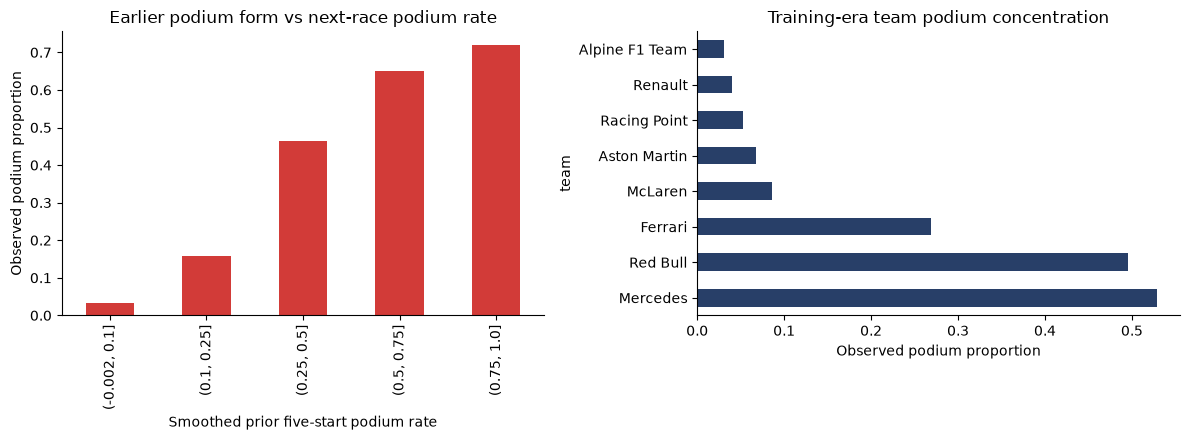

**Interpretation:** next-race podium rates range from 3.3% to 72.0% across the displayed prior-form groups. Counts show how much evidence supports each estimate. Team concentration motivates a team-form benchmark; a model must beat those simple signals to add value.

In [4]:
eda=historical[historical.season.between(2019,2023)].copy()
eda['form_band']=pd.cut(eda.driver_podium5,bins=[-0.001,.1,.25,.5,.75,1],include_lowest=True)
form=eda.groupby('form_band',observed=True).podium.agg(['size','mean'])
display(form.rename(columns={'size':'driver_starts','mean':'next_race_podium_rate'}))
team_rates=eda.groupby('team').podium.agg(['size','mean']).query('size >= 50').sort_values('mean',ascending=False)
display(team_rates.head(8))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
form['mean'].plot.bar(ax=axes[0],color='#d23b38',title='Earlier podium form vs next-race podium rate')
axes[0].set_ylabel('Observed podium proportion'); axes[0].set_xlabel('Smoothed prior five-start podium rate')
team_rates['mean'].head(8).plot.barh(ax=axes[1],color='#283f68',title='Training-era team podium concentration')
axes[1].set_xlabel('Observed podium proportion'); fig.tight_layout()
fig.savefig(ROOT/'figures/training_eda.png',dpi=160); plt.show()
display(Markdown(f"**Interpretation:** next-race podium rates range from {form['mean'].min():.1%} to {form['mean'].max():.1%} across the displayed prior-form groups. Counts show how much evidence supports each estimate. Team concentration motivates a team-form benchmark; a model must beat those simple signals to add value."))

## 4. Predictive methods and fair baselines

**Three baselines:** field prevalence (3/number of entrants), smoothed recent driver podium rate, and smoothed recent team podium rate. The first contains no ranking information; the other two represent straightforward fan heuristics.

**Logistic regression:** estimates podium log-odds from standardized features. It is simple and interpretable, but assumes additive effects on log-odds.

**Random forest:** 120 trees, maximum depth 6, minimum leaf size 15. It captures nonlinear relationships and interactions while constraining complexity. Both models use fixed settings; there is no extensive parameter search, class rebalancing, or claim that complexity guarantees improvement.

**Walk-forward evaluation:** before each historical forecast, fit only to races that already happened. All drivers from a race remain together. 2024 is the development period and chooses the learned model with lower mean race-level Brier score. 2025 is the primary subsequent evaluation; completed 2026 races provide a separate current-era diagnostic. Earlier completed races in an evaluation season can train the next forecast, mirroring rolling deployment; this is not a frozen-model test.

The models are selected using 2024 only. Future forecasts then refit that selected method on all eligible completed results. This retrospectively designed backtest is not an independently preregistered experiment; prospective forecasts are the next stronger test.

In [5]:
predictions,metrics,selected=backtest(historical)
display(metrics.round(4))
print('Selected using 2024 probability error:',selected)
intervals=race_bootstrap(predictions,selected)
display(intervals.round(5))

Backtest 2024-1 Bahrain Grand Prix


Backtest 2024-2 Saudi Arabian Grand Prix


Backtest 2024-3 Australian Grand Prix


Backtest 2024-4 Japanese Grand Prix


Backtest 2024-5 Chinese Grand Prix


...

Backtest 2026-16 Bahrain Grand Prix in Malaysia


Backtest 2026-17 Singapore Grand Prix


,season,model,races,brier,log_loss,mean_podium_hits_of_3,exact_podium_set_rate,average_precision,roc_auc
0,2024,Field prevalence,24,0.1277,0.4233,0.9167,0.0000,0.1506,0.5012
1,2024,Logistic regression,24,0.0908,0.2775,1.5833,0.1250,0.5017,0.8907
2,2024,Random forest,24,0.0908,0.2798,1.5833,0.0833,0.4663,0.8775
3,2024,Recent podium form,24,0.0974,0.3108,1.4167,0.0417,0.4264,0.8394
4,2024,Team podium form,24,0.0934,0.2918,1.5417,0.1250,0.4717,0.8718
5,2025,Field prevalence,24,0.1277,0.4233,0.2083,0.0000,0.1506,0.5012
6,2025,Logistic regression,24,0.0748,0.2395,1.8750,0.1667,0.6272,0.9205
7,2025,Random forest,24,0.0745,0.2444,1.9583,0.1250,0.6379,0.9100
8,2025,Recent podium form,24,0.0833,0.2773,1.7083,0.1667,0.5671,0.8719
9,2025,Team podium form,24,0.0903,0.2967,1.6250,0.0417,0.5296,0.8532


Selected using 2024 probability error: Random forest


,season,selected,baseline,brier_difference,ci_low,ci_high
0,2025,Random forest,Recent podium form,-0.00873,-0.01373,-0.0036
1,2025,Random forest,Team podium form,-0.01574,-0.02206,-0.0099


## 5. Interpret forecast quality at the race level

**Brier score** measures squared probability error (lower is better); **log loss** penalizes confident wrong predictions. Average precision and ROC-AUC evaluate ranking across driver starts. Average precision is not precision for the three named picks.

**Mean podium hits out of three** is directly understandable: how many members of our three-driver shortlist actually reached the podium? **Exact podium set** requires all three correct, regardless of their order. These do not measure an exact finishing order. Ties are broken alphabetically, without looking at outcomes. Randomly picking three of N entrants has expected 9/N podium hits; tied field-prevalence scores use the deterministic tie rule and are not a random simulation.

The paired bootstrap resamples **whole races**, keeping dependence among drivers intact. A negative Brier difference favors the selected model; an interval spanning zero does not establish an improvement. These intervals do not account for every modeling decision or future regulation changes.

**Primary evaluation:** Random forest has Brier score **0.075** and averages **1.96 of 3 podium drivers** in 2025. The strongest probability baseline is **Recent podium form** (Brier **0.083**). Model-minus-baseline difference: **-0.009**; lower favors the model. Read the race-block interval before interpreting this as a reliable advantage.

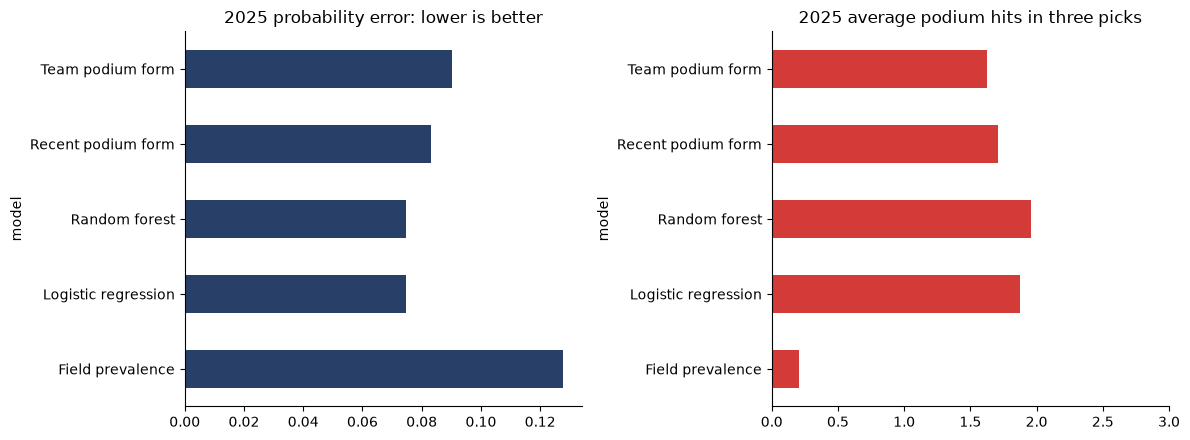

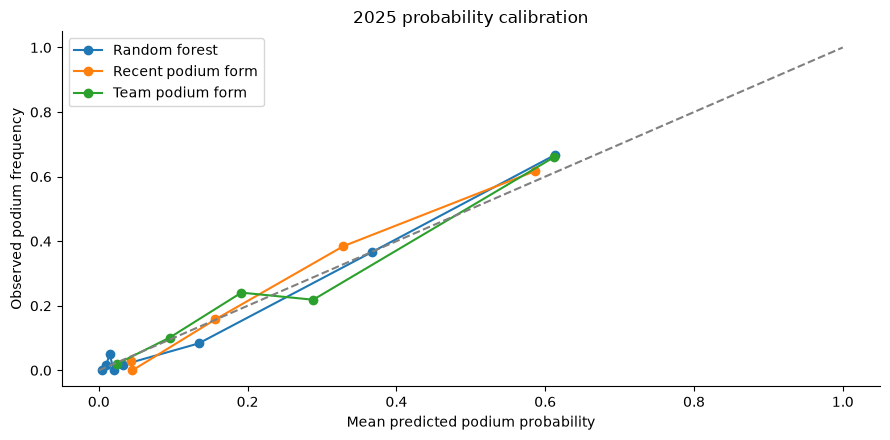

**Calibration interpretation:** points close to the diagonal indicate predicted risks broadly match observed frequencies in those bins. Above the line means underprediction; below means overprediction. Bins are descriptive and are not a guarantee for individual drivers or future races. No separate calibration model has been fitted in this first version.

In [6]:
holdout=metrics[metrics.season==2025].set_index('model')
chosen=holdout.loc[selected]
best_baseline=holdout.loc[['Recent podium form','Team podium form']].brier.idxmin()
delta=float(chosen.brier-holdout.loc[best_baseline].brier)
display(Markdown(f"**Primary evaluation:** {selected} has Brier score **{chosen.brier:.3f}** and averages **{chosen.mean_podium_hits_of_3:.2f} of 3 podium drivers** in 2025. The strongest probability baseline is **{best_baseline}** (Brier **{holdout.loc[best_baseline].brier:.3f}**). Model-minus-baseline difference: **{delta:+.3f}**; lower favors the model. Read the race-block interval before interpreting this as a reliable advantage."))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
holdout.brier.plot.barh(ax=axes[0],color='#283f68',title='2025 probability error: lower is better')
holdout.mean_podium_hits_of_3.plot.barh(ax=axes[1],color='#d23b38',title='2025 average podium hits in three picks')
axes[1].set_xlim(0,3); fig.tight_layout(); fig.savefig(ROOT/'figures/holdout_comparison.png',dpi=160); plt.show()
from sklearn.calibration import calibration_curve
fig,ax=plt.subplots()
for name in [selected,'Recent podium form','Team podium form']:
    subset=predictions[(predictions.season==2025)&(predictions.model==name)]
    observed,estimated=calibration_curve(subset.actual_podium,subset.p_podium,n_bins=8,strategy='quantile')
    ax.plot(estimated,observed,'o-',label=name)
ax.plot([0,1],[0,1],'--',color='gray'); ax.set(xlabel='Mean predicted podium probability',ylabel='Observed podium frequency',title='2025 probability calibration'); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'figures/calibration.png',dpi=160); plt.show()
display(Markdown('**Calibration interpretation:** points close to the diagonal indicate predicted risks broadly match observed frequencies in those bins. Above the line means underprediction; below means overprediction. Bins are descriptive and are not a guarantee for individual drivers or future races. No separate calibration model has been fitted in this first version.'))

## 6. Examine when the model fails and how the current era differs

An honest forecast includes its misses. We report the races with the fewest correct podium picks, rather than only showcase wins. These are errors to investigate; results alone cannot establish whether weather, strategy, collisions, or safety cars caused them.

2026 is separately reported because performance relationships can change across seasons. A small current-season sample limits certainty. Older driver/team form can be stale after a regulation change, driver transfer, or upgrade.

In [7]:
errors=[]
for race_id,race in predictions[(predictions.model==selected)&(predictions.season==2025)].groupby('race_id'):
    picks=race.sort_values(['p_podium','driver'],ascending=[False,True]).head(3)
    actual=race[race.actual_podium==1]
    errors.append({'race_id':race_id,'hits':int(picks.actual_podium.sum()),'picks':', '.join(picks.driver),'actual_podium':', '.join(actual.driver)})
errors=pd.DataFrame(errors).sort_values(['hits','race_id'])
display(errors.head(6)); errors.to_csv(ROOT/'reports/2025_race_errors.csv',index=False)
display(metrics[metrics.season==2026].round(4))
current=metrics[(metrics.season==2026)&(metrics.model==selected)].iloc[0]
display(Markdown(f"**Current-era diagnostic:** across {int(current.races)} completed 2026 races, {selected} averages **{current.mean_podium_hits_of_3:.2f} podium hits** and Brier **{current.brier:.3f}**. This is a separate descriptive check, not a basis for choosing a different winner after seeing holdout results."))

,race_id,hits,picks,actual_podium
1,2025-10,1,"Oscar Piastri, Lando Norris, Max Verstappen","George Russell, Max Verstappen, Andrea Kimi An..."
6,2025-15,1,"Oscar Piastri, Lando Norris, Charles Leclerc","Oscar Piastri, Max Verstappen, Isack Hadjar"
8,2025-17,1,"Oscar Piastri, Lando Norris, Max Verstappen","Max Verstappen, George Russell, Carlos Sainz"
19,2025-5,1,"Lando Norris, Oscar Piastri, George Russell","Oscar Piastri, Max Verstappen, Charles Leclerc"
0,2025-1,2,"Lando Norris, Charles Leclerc, George Russell","Lando Norris, Max Verstappen, George Russell"
2,2025-11,2,"Oscar Piastri, Lando Norris, Max Verstappen","Lando Norris, Oscar Piastri, Charles Leclerc"


,season,model,races,brier,log_loss,mean_podium_hits_of_3,exact_podium_set_rate,average_precision,roc_auc
10,2026,Field prevalence,17,0.1178,0.3983,0.8235,0.0000,0.1364,0.5000
11,2026,Logistic regression,17,0.0899,0.2701,1.3529,0.0000,0.4333,0.8854
12,2026,Random forest,17,0.0841,0.2547,1.5882,0.0000,0.4981,0.8969
13,2026,Recent podium form,17,0.0880,0.2849,1.5294,0.0588,0.4437,0.8538
14,2026,Team podium form,17,0.0863,0.2681,1.4118,0.0000,0.4591,0.8824


**Current-era diagnostic:** across 17 completed 2026 races, Random forest averages **1.59 podium hits** and Brier **0.084**. This is a separate descriptive check, not a basis for choosing a different winner after seeing holdout results.

## 7. Produce the next-race forecast

The selected method is refitted to all completed 2019–2026 race labels available by the cutoff. The three highest podium probabilities form the model's shortlist. We retain the baselines alongside the forecast so disagreements are visible.

Each probability is an **independent marginal podium estimate**. Their sum is not forced to three, and this model does not generate a jointly coherent race simulation. The displayed ranking is podium likelihood, not expected classified finishing position. A coherent ranking/simulation model would be a separate extension.

Entrants and teams are carried forward from the latest completed race and must be updated if the next entry list differs. Current-weekend qualifying, practice, forecast weather, tyre choice, penalties, and live strategy are not included. This is the **pre-weekend** edition.

,podium_likelihood_rank,driver,team,podium_probability,recent_form_probability,team_form_probability
0,1,Andrea Kimi Antonelli,Mercedes,62.5%,61.0%,52.3%
1,2,Max Verstappen,Red Bull,61.7%,75.3%,52.3%
2,3,George Russell,Mercedes,41.4%,32.5%,52.3%
3,4,Lando Norris,McLaren,39.9%,18.2%,10.6%
4,5,Lewis Hamilton,Ferrari,33.6%,18.2%,18.9%
5,6,Charles Leclerc,Ferrari,32.5%,18.2%,18.9%
6,7,Isack Hadjar,Red Bull,31.2%,18.2%,52.3%
7,8,Oscar Piastri,McLaren,18.0%,3.9%,10.6%
8,9,Pierre Gasly,Alpine F1 Team,8.8%,3.9%,2.3%
9,10,Liam Lawson,RB F1 Team,3.6%,3.9%,2.3%


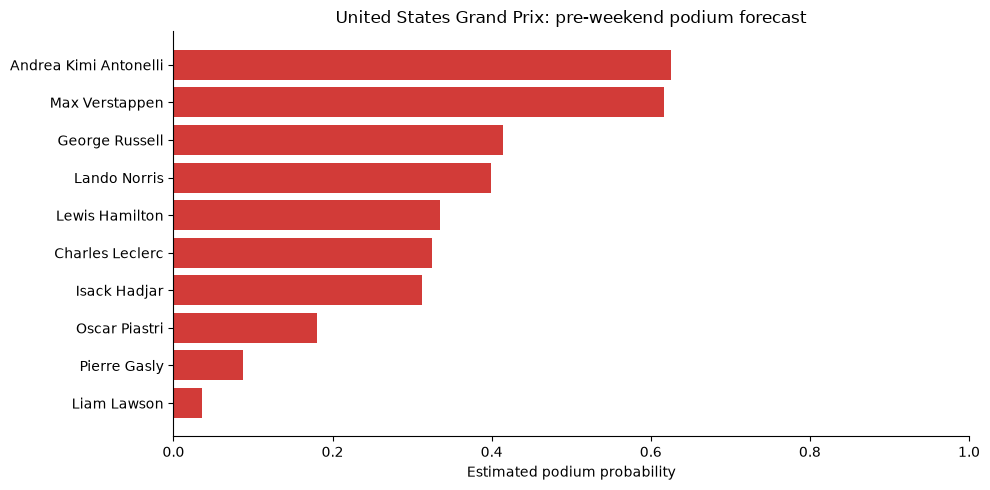

Sum of independent podium probabilities: 3.518
Forecast saved under forecasts/ with cutoff in filename.


In [8]:
forecast,fitted=predict_next(historical,future,selected,manifest)
forecast_display=forecast[['podium_likelihood_rank','driver','team','podium_probability','recent_form_probability','team_form_probability']].copy()
for column in ['podium_probability','recent_form_probability','team_form_probability']:
    forecast_display[column]=forecast_display[column].map(lambda value:f'{value:.1%}')
display(forecast_display)
fig,ax=plt.subplots(figsize=(10,5))
top=forecast.head(10).iloc[::-1]
ax.barh(top.driver,top.podium_probability,color='#d23b38')
ax.set(xlabel='Estimated podium probability',title=f"{manifest['next_race']}: pre-weekend podium forecast")
ax.set_xlim(0,1); fig.tight_layout(); fig.savefig(ROOT/'figures/next_race_forecast.png',dpi=160); plt.show()
print('Sum of independent podium probabilities:',round(forecast.podium_probability.sum(),3))
print('Forecast saved under forecasts/ with cutoff in filename.')

## 8. Explain the evidence and practical outcome

For interpretation, a feature's contribution should be measured on later data rather than explained solely by its training importance. We use permutation importance on the primary holdout: fit the selected method through 2024, then shuffle one feature at a time in 2025. This is a separate frozen-fit diagnostic; it does not replace the rolling backtest. Correlated features can share information, so importance is not causal attribution.

In [9]:
from forecast import model
from sklearn.inspection import permutation_importance
train=historical[historical.season.between(2019,2024)]
test=historical[historical.season==2025]
interpret_model=model(selected).fit(train[FEATURES],train.podium)
importance=permutation_importance(interpret_model,test[FEATURES],test.podium,scoring='neg_brier_score',n_repeats=5,random_state=42)
importance_table=pd.DataFrame({'feature':FEATURES,'increase_in_brier_when_shuffled':importance.importances_mean,'repeat_sd':importance.importances_std}).sort_values('increase_in_brier_when_shuffled',ascending=False)
display(importance_table); importance_table.to_csv(ROOT/'reports/feature_importance.csv',index=False)
strongest=importance_table.iloc[0].feature
ci=intervals[intervals.baseline==best_baseline].iloc[0]
evidence=('The paired race-bootstrap interval is below zero, supporting lower probability error against this baseline in the evaluated sample.' if ci.ci_high<0 else 'The paired race-bootstrap interval does not establish a reliable probability-error advantage against this baseline.' if ci.ci_low<=0<=ci.ci_high else 'The paired race-bootstrap interval favors the baseline over the selected model.')
conclusion=f"""## Conclusion: what did the project demonstrate?

The selected method is **{selected}**, chosen on 2024. In the primary 2025 evaluation it averages **{chosen.mean_podium_hits_of_3:.2f} correct podium drivers out of three** with Brier **{chosen.brier:.3f}**, compared with **{holdout.loc[best_baseline].brier:.3f}** for {best_baseline}. {evidence}

The largest individual permutation effect in the frozen-fit diagnostic belongs to **{strongest}**. This helps explain where predictive information comes from; it does not establish causality or isolate related signals perfectly.

The theoretical value is a reproducible way for fans and analysts to move from intuition to explicit probabilities, compare contenders, and track forecast quality over time. The contribution is strongest when a forecast improves on a simple rule, remains calibrated, and is published before the outcome. No revenue, betting profit, or guaranteed racing outcome is established.

The next forecast is for **{manifest['next_race']} on {manifest['next_date']}**. Its shortlist is **{', '.join(forecast.head(3).driver)}**. These are contenders ranked by estimated podium likelihood, not a prediction of the exact podium order. The roster is provisional and the probabilities omit upcoming-weekend information.

The next step is to preserve this dated forecast before the race and score it afterward without rewriting the predictions. Over multiple prospective races, that record can show whether retrospective findings survive real use. Future work: a separate post-qualifying edition, verified entrant lists, recency weighting/regime sensitivity, race-level calibration validation, and a coherent ranking model.
"""
display(Markdown(conclusion))
(ROOT/'reports/conclusion.md').write_text(conclusion)
summary={'manifest':manifest,'selected_model':selected,'selection_period':2024,'primary_evaluation_period':2025,'best_baseline':best_baseline,'primary_metrics':chosen.to_dict(),'brier_difference_vs_best_baseline':delta,'bootstrap':ci.to_dict(),'forecast_shortlist':forecast.head(3).driver.tolist()}
(ROOT/'reports/results.json').write_text(json.dumps(summary,indent=2,default=str))

,feature,increase_in_brier_when_shuffled,repeat_sd
6,season_podium,9.189232e-03,1.244554e-03
1,driver_grid5,8.898445e-03,1.302888e-03
0,driver_finish5,3.593553e-03,8.135560e-04
4,team_finish10,3.319747e-03,1.042926e-03
2,driver_podium5,1.775809e-03,3.709793e-04
5,team_podium10,1.754977e-03,4.159778e-04
7,circuit_finish3,6.920444e-04,2.495536e-04
8,experience,4.015379e-05,1.243052e-04
9,history_count,1.193824e-07,1.232303e-07
10,field_size,0.000000e+00,0.000000e+00


## Conclusion: what did the project demonstrate?

The selected method is **Random forest**, chosen on 2024. In the primary 2025 evaluation it averages **1.96 correct podium drivers out of three** with Brier **0.075**, compared with **0.083** for Recent podium form. The paired race-bootstrap interval is below zero, supporting lower probability error against this baseline in the evaluated sample.

The largest individual permutation effect in the frozen-fit diagnostic belongs to **season_podium**. This helps explain where predictive information comes from; it does not establish causality or isolate related signals perfectly.

The theoretical value is a reproducible way for fans and analysts to move from intuition to explicit probabilities, compare contenders, and track forecast quality over time. The contribution is strongest when a forecast improves on a simple rule, remains calibrated, and is published before the outcome. No revenue, betting profit, or guaranteed racing outcome is established.

The next forecast is for **United States Grand Prix on 2026-10-25**. Its shortlist is **Andrea Kimi Antonelli, Max Verstappen, George Russell**. These are contenders ranked by estimated podium likelihood, not a prediction of the exact podium order. The roster is provisional and the probabilities omit upcoming-weekend information.

The next step is to preserve this dated forecast before the race and score it afterward without rewriting the predictions. Over multiple prospective races, that record can show whether retrospective findings survive real use. Future work: a separate post-qualifying edition, verified entrant lists, recency weighting/regime sensitivity, race-level calibration validation, and a coherent ranking model.


1321